# 9a. Sea ice: calculations

From the sea-ice files to everything notebook 09b draws:

1. how one field goes onto the 2.5° grid of the temperature, step by step;
2. every model's sea ice on that grid (the sample, or the CEDA files on JASMIN), and ERA5's;
3. seasonal means;
4. the sea-ice extent and the ice edge;
5. ERA5's, and each model's historical over the same years;
6. ERA5 among each model's members (JASMIN);
7. the sea ice next to the temperature changes of notebook 03.

Results are saved under `results/siconc/<RUN>/`; notebooks 04 and 07 read `extent` and `climatology` too.

## Setup

In [1]:
import sys
sys.path[:0] = ['..']   # this repository: the extant package and plotting_modules

import logging
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from extant import convert, paths, preprocessing as pp, sea_ice, significance as sig, storage
from extant import era5_evaluation as ev
from extant.datatree import skip_empty, tree_to_dataset
from extant.logger import setup_logging
from extant.plots import methods

logger = setup_logging('extant', logging.INFO)
xr.set_options(display_expand_attrs=False, display_expand_data=False)
#(t): Models with fewer members are NaN in the members they lack once side by side; their std has no degrees of freedom
warnings.filterwarnings('ignore', message='Degrees of freedom <= 0 for slice', category=RuntimeWarning)

In [2]:
#(t): The map projection of every quick look
POLAR = dict(subplot_kws=dict(projection=ccrs.SouthPolarStereo()), transform=ccrs.PlateCarree())

## Settings

In [3]:
#(t): The models and the experiments (notebook 01's), and the seasons in the order of every figure
MODELS = ['CanESM5', 'GISS-E2-1-G', 'HadGEM3-GC31-LL', 'MIROC6', 'MPI-ESM1-2-LR', 'NorESM2-LM']
EXPERIMENTS = ['hist-nat', 'hist-aer', 'hist-totalO3', 'hist-GHG', 'historical']
SEASONS = ['DJF', 'MAM', 'JJA', 'SON']

In [4]:
#(t): The model of the one-model quick looks
MODEL = 'CanESM5'

In [5]:
#(t): Concentration (%) from which a cell counts as ice: the usual definition of the extent
THRESHOLD = 15.0

In [6]:
#(t): Every record is cut where historical ends, so "the final years" are the same years in every experiment
LAST_MONTH = '2014-12'

#(t): The final years compared with hist-nat (as in notebook 03)
WINDOW = 21

#(t): The years compared with ERA5: the satellite era, up to the last whole year of historical (DJF 2013)
ERA5_YEARS = slice(1979, 2013)

In [7]:
#(t): CanESM5 and MIROC6 have hist-stratO3 on CEDA rather than hist-totalO3: it stands in for their ozone run
OZONE_NAMES = {'hist-stratO3': 'hist-totalO3'}

In [8]:
#(t): The 2.5° grid of the temperature (notebook 01's stores): cell centres every 2.5°, from 87.5°S to 40°S and from
#(t): 180°W to 177.5°E. Each cell reaches 1.25° either side of its centre
GRID_LAT = np.arange(-87.5, -40 + 1.25, 2.5)
GRID_LON = np.arange(-180.0, 180.0, 2.5)

In [9]:
#(t): Mean radius of the Earth (km): every area here is in km²
EARTH_RADIUS = 6371.0

In [10]:
#(t): Each sea-ice variable's grid: the variable in its cell-area file, and the names of its points' latitude and
#(t): longitude. siconc is on the ocean model's grid (2-D latitude and longitude); siconca, which GISS-E2-1-G has
#(t): instead, on the atmosphere model's regular grid (1-D lat and lon)
AREA_VARIABLES = {'siconc': 'areacello', 'siconca': 'areacella'}
POSITION_NAMES = {'siconc': ('latitude', 'longitude'), 'siconca': ('lat', 'lon')}

## Dask cluster (JASMIN)

For section 2's full data: the CEDA files and ERA5's daily files.

In [12]:
from extant import jasmin

gateway, cluster, client = jasmin.connect(n_workers=20, wait_for=6)
jasmin.upload_package(client)
client

Connection method: Cluster object,Cluster type: dask_gateway.GatewayCluster
Dashboard: /_jasmin/proxy/dask-gateway/clusters/5f67ebe9f7c14fa68cc1fb5371ad6799/status,


## 1. How a field goes onto the 2.5° grid

**Grids.** A model doesn't give a value at every spot on Earth. It splits the surface into small boxes, called *cells*, and gives one value per cell: here, the % of the cell covered by sea ice. The layout of the cells is the model's *grid*. A cell's value belongs to its centre, so a grid can also be thought of as a set of *points*, one per cell.

Two grids meet in this notebook:

- **the 2.5° grid** of the temperature (notebook 01): cells 2.5° of latitude by 2.5° of longitude, in neat rows and columns;
- **each model's ocean grid**, where the sea ice comes from: smaller cells (about 1°), laid out differently in each model.

To compare the sea ice with the temperature, the sea ice has to go onto the 2.5° grid. Each 2.5° cell gets the area-weighted mean of the model points inside it, leaving out land:

$$c_\text{cell} = \frac{\sum_k a_k\, c_k}{\sum_k a_k}$$

over the model points $k$ inside the 2.5° cell that have a concentration $c_k$; $a_k$ is the area of the model cell around point $k$. The bottom sum is how much of the 2.5° cell is ocean.

Step by step on one month of CanESM5 (the sample in this repository): (1) the 2.5° grid; (2) the model's grid and what its file holds; (3) which 2.5° cell each model point is in; (4) the mean in each 2.5° cell.

**(1) The 2.5° grid**

Its cells line up in rows (every cell in a row is at the same latitude) and columns (every cell in a column at the same longitude). So the whole grid is two lists: the latitude of each row's centre and the longitude of each column's centre. Each cell reaches 1.25° either side of its centre. The rows are numbered 0, 1, 2, … from the south (the **lat index**) and the columns from 180°W (the **lon index**). Step 3 uses these numbers.

In [ ]:
#(t): The latitudes of the 2.5° grid's rows (cell centres), south to north: 20 rows, 87.5°S to 40°S
GRID_LAT

In [ ]:
#(t): ... and the longitudes of its columns, west to east: 144 columns, 180°W to 177.5°E
GRID_LON

In [ ]:
#(t): Each row's and column's number: the lat index (0 at 87.5°S) and the lon index (0 at 180°W)
grid_lat_index_da = xr.DataArray(np.arange(GRID_LAT.size), dims='lat', coords={'lat': GRID_LAT})
grid_lon_index_da = xr.DataArray(np.arange(GRID_LON.size), dims='lon', coords={'lon': GRID_LON})
grid_lat_index_da

In [ ]:
#(t): Quick look: the 2.5° grid as a chessboard on a flat latitude-longitude plot. Every square is one cell
grid_checker_da = (grid_lat_index_da + grid_lon_index_da) % 2
grid_checker_da.plot(cmap='Greys', vmin=-1, vmax=3, add_colorbar=False, figsize=(14, 3));

**(2) The model's grid, and what its file holds**

In [13]:
#(t): The sample's folder: one member of each model and experiment for 2013-2014, on each model's own grid
sample_dir = paths.SEA_ICE_SAMPLE_DIR / 'lesfmip'
sample_dir

PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip')

In [14]:
#(t): MODEL's historical file, and the file of its grid's cell areas (areacello: the ocean model's)
example_path = sample_dir / f'{MODEL}_historical_siconc_r1i1p1f1_gn.nc'
example_area_path = sample_dir / f'{MODEL}_areacello_gn.nc'
example_path, example_area_path

(PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_historical_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_areacello_gn.nc'))

In [15]:
#(t): The file as it is
example_native_ds = xr.open_dataset(example_path)
example_native_ds

<xarray.Dataset> Size: 6MB
Dimensions:             (time: 24, bnds: 2, j: 88, i: 360, vertices: 4)
Coordinates:
  * time                (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16...
  * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 253kB ...
    longitude           (j, i) float64 253kB ...
    type                |S7 7B ...
Dimensions without coordinates: bnds, vertices
Data variables:
    time_bnds           (time, bnds) object 384B ...
    vertices_latitude   (j, i, vertices) float64 1MB ...
    vertices_longitude  (j, i, vertices) float64 1MB ...
    siconc              (time, j, i) float32 3MB ...
Attributes: (53)

**What is in the file**

- `siconc` (time, j, i): the concentration at each model point, each month (%); empty over land.
- `latitude`, `longitude` (j, i): where each model point is.
- `j`, `i`: the file keeps the model points in arrays of 88 × 360 values (the sample stops at 40°S). `j` (0–87) and `i` (0–359) are a point's place in these arrays, not on the Earth. The same `j, i` in each array is the same point: `latitude[50, 2]`, `longitude[50, 2]` and `siconc[:, 50, 2]` are where one point is and how much ice it has. MIROC6 calls them `y` and `x`.
- `vertices_latitude`, `vertices_longitude` (j, i, vertices): the four corners of each model cell. Not used.
- `time_bnds`: the start and end of each month. Not used.
- `type`: a label, `sea_ice`. Not used.

In [ ]:
#(t): One model point (j = 50, i = 2): where it is and its ice in September 2013 (62.7°S, 75.5°E, 96%).
#(t): Steps 3 and 4 follow this point
one_point = dict(j=50, i=2)
(float(example_native_ds['latitude'].isel(one_point)),
 float(example_native_ds['longitude'].isel(one_point)),
 float(example_native_ds['siconc'].sel(time='2013-09').isel(one_point).squeeze()))

**Why latitude and longitude are 2-D arrays.** On the 2.5° grid one latitude per row is enough. An ocean model's rows don't have to follow latitude circles. To keep the grid's own poles off the ocean, a model moves them onto land, and its rows bend round them. Then the points along one row are at different latitudes, so every point needs its own latitude and longitude. CanESM5's grid uses the real South Pole, so south of 40°S its rows happen to be latitude circles. MPI-ESM1-2-LR moves its southern pole off the South Pole, so its rows are bent here.

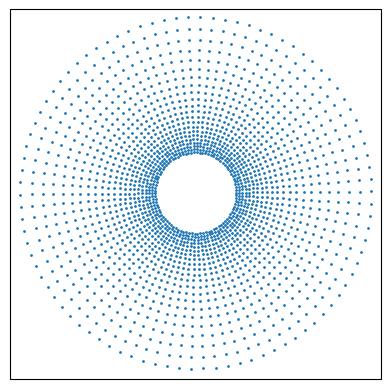

In [18]:
#(t): Quick look: every fourth row and column of the points on a map
fig, ax = plt.subplots(subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
ax.scatter(example_native_ds['longitude'][::4, ::4], example_native_ds['latitude'][::4, ::4], s=1, transform=ccrs.PlateCarree())
ax.set_extent([-180, 180, -90, -40], ccrs.PlateCarree());

In [ ]:
#(t): MPI-ESM1-2-LR's file, to compare its grid with CanESM5's
mpi_native_ds = xr.open_dataset(sample_dir / 'MPI-ESM1-2-LR_historical_siconc_r1i1p1f1_gn.nc')

In [ ]:
#(t): Quick look: the latitude along one row of points, all the way round. CanESM5's (j = 50) stays at 62.7°S;
#(t): MPI-ESM1-2-LR's (j = 40) swings between 74°S and 62°S
example_native_ds['latitude'].isel(j=50).plot.line(x='i', label='CanESM5, j = 50')
mpi_native_ds['latitude'].isel(j=40).plot.line(x='i', label='MPI-ESM1-2-LR, j = 40')
plt.legend();

**Drawing a model's field.** `.plot()` on an array on (j, i) draws it by place in the arrays (`i` across, `j` up). That's a picture of the arrays, not a map. For a map, xarray needs each point's position: `x='longitude', y='latitude'`.

In [ ]:
#(t): One month, September 2013, at every model point
example_native_da = example_native_ds['siconc'].sel(time='2013-09').squeeze('time', drop=True)

In [ ]:
#(t): Quick look: drawn by place in the arrays (left: Antarctica is the white at the bottom, the lowest j), and on a
#(t): map, each point at its own latitude and longitude (right)
fig = plt.figure(figsize=(12, 4.5))
ax_arrays = fig.add_subplot(1, 2, 1)
example_native_da.plot(ax=ax_arrays, vmin=0, vmax=100)
ax_map = fig.add_subplot(1, 2, 2, projection=ccrs.SouthPolarStereo())
example_native_da.plot(ax=ax_map, x='longitude', y='latitude', transform=ccrs.PlateCarree(), vmin=0, vmax=100);

In [19]:
#(t): The file of the grid's cell areas: areacello, the ocean model's, in m², on the same (j, i)
example_area_ds = xr.open_dataset(example_area_path)
example_area_ds

<xarray.Dataset> Size: 3MB
Dimensions:             (j: 88, i: 360, vertices: 4)
Coordinates:
  * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 253kB ...
    longitude           (j, i) float64 253kB ...
Dimensions without coordinates: vertices
Data variables:
    vertices_latitude   (j, i, vertices) float64 1MB ...
    vertices_longitude  (j, i, vertices) float64 1MB ...
    areacello           (j, i) float32 127kB ...
Attributes: (52)

In [ ]:
#(t): Each model cell's area, in km² (smaller towards the pole)
example_point_area_da = example_area_ds['areacello'] / 1e6
example_point_area_da.plot(x='longitude', y='latitude', **POLAR);

**The two grids together.** Zoomed in on a small patch (56–69°S, 0–14°E): the model's points (dots) and the 2.5° grid's cells (blue lines). Here CanESM5's points are 1° apart in longitude and about 0.5° apart in latitude, so each 2.5° cell holds about a dozen. Each 2.5° cell will get the mean of the points inside it, but first each point has to be matched to its cell.

In [ ]:
#(t): Quick look: a small patch of the model's points (dots) and the 2.5° grid's cell edges (blue lines)
patch_da = ((example_native_ds['latitude'] > -68.75) & (example_native_ds['latitude'] < -56.25)
            & (example_native_ds['longitude'] < 13.75))
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(example_native_ds['longitude'].where(patch_da), example_native_ds['latitude'].where(patch_da), s=15, color='k')
ax.hlines(np.arange(-68.75, -56, 2.5), -1.25, 13.75, color='C0')
ax.vlines(np.arange(-1.25, 14, 2.5), -68.75, -56.25, color='C0')
ax.set(xlabel='longitude (°E)', ylabel='latitude (°)', xlim=(-1.25, 13.75), ylim=(-68.75, -56.25));

**(3) Which 2.5° cell each model point is in**

Each model point gets the lat index of the 2.5° cell it's in, and from that the cell's centre. The 2.5° rows start at 88.75°S (the southern edge of row 0) and are 2.5° tall, so for the point above at 62.66°S:

1. **How far north of 88.75°S it is, counted in 2.5° steps:** (−62.66 + 88.75) / 2.5 = **10.44**. This is a position, like a reading on a ruler, so it needn't be whole: the point is past 10 whole rows and 44% of the way across the next.
2. **The lat index:** round down, **10**.
3. **That row's centre:** −87.5 + 2.5 × 10 = **62.5°S**.

```
lat index:     9           10           11
       |-----------|-----------|-----------|
   66.25°S     63.75°S     61.25°S     58.75°S
                     ^
           the point at 62.66°S: 10.44 steps from 88.75°S → in lat index 10
```

Longitude works the same way, from the western edge of column 0 (181.25°W): 75.5°E is (75.5 + 181.25) / 2.5 = 102.7 steps, so lon index 102, centred on −180 + 2.5 × 102 = **75°E**. The `% 360` puts the models' 0–360° longitudes onto the grid's −180–180°, so 350°E and 10°W land in the same column.

In [ ]:
#(t): 1. How far north of 88.75°S each model point is, in 2.5° steps (the point above: 10.44)
example_lat_steps_da = (example_native_ds['latitude'] + 88.75) / 2.5
float(example_lat_steps_da.isel(one_point))

In [ ]:
#(t): 2. The lat index of the 2.5° cell each model point is in: rounded down (10.44 -> 10)
example_lat_index_da = np.floor(example_lat_steps_da)
float(example_lat_index_da.isel(one_point))

In [ ]:
#(t): 3. That cell's centre latitude (10 -> 62.5°S)
example_cell_lat_da = -87.5 + 2.5 * example_lat_index_da
float(example_cell_lat_da.isel(one_point))

In [ ]:
#(t): Quick look: one column of model points (i = 0), south to north. The dots are the points' own latitudes, the line
#(t): their 2.5° cells' centres. The points along one flat step share a cell
example_native_ds['latitude'].isel(i=0).plot.line(x='j', marker='.', ls='none', label="the point's own latitude")
example_cell_lat_da.isel(i=0).plot.line(x='j', drawstyle='steps-mid', label="the centre of its 2.5° cell")
plt.legend();

In [ ]:
#(t): The same for longitude, in one go: the centre longitude of each model point's 2.5° cell (75.5°E -> 75°E)
example_cell_lon_da = -180 + 2.5 * np.floor(((example_native_ds['longitude'] + 181.25) % 360) / 2.5)
float(example_cell_lon_da.isel(one_point))

In [ ]:
#(t): Check: no point is more than half a cell (1.25°) from its cell's centre, in latitude or in longitude (taken
#(t): round the globe)
(float(abs(example_cell_lat_da - example_native_ds['latitude']).max()),
 float(abs((example_cell_lon_da - example_native_ds['longitude'] + 180) % 360 - 180).max()))

In [ ]:
#(t): Quick look: the patch again, each point coloured by its 2.5° cell (alternating like a chessboard), with the
#(t): cells' edges and centres (x). The points of one colour inside one square are averaged together in step 4
checker_da = (example_cell_lat_da / 2.5 + example_cell_lon_da / 2.5) % 2
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(example_native_ds['longitude'].where(patch_da), example_native_ds['latitude'].where(patch_da),
           c=checker_da.where(patch_da), cmap='coolwarm', s=30)
ax.hlines(np.arange(-68.75, -56, 2.5), -1.25, 13.75, color='0.5', lw=0.8)
ax.vlines(np.arange(-1.25, 14, 2.5), -68.75, -56.25, color='0.5', lw=0.8)
ax.scatter(*np.meshgrid(np.arange(0, 13, 2.5), np.arange(-67.5, -57, 2.5)), marker='x', color='k', s=40)
ax.set(xlabel='longitude (°E)', ylabel='latitude (°)', xlim=(-1.25, 13.75), ylim=(-68.75, -56.25));

**(4) The mean in each 2.5° cell**

In [ ]:
#(t): Each point's area where it is ocean, i.e. where it has a concentration (km²; empty over land)
example_ocean_point_area_da = example_point_area_da.where(example_native_da.notnull())
example_ocean_point_area_da.plot(x='longitude', y='latitude', **POLAR);

In [ ]:
#(t): Each point's area times its concentration (km² × %)
example_weighted_siconc_da = example_point_area_da * example_native_da
example_weighted_siconc_da.plot(x='longitude', y='latitude', **POLAR);

In [31]:
#(t): The two side by side, each point labelled with the centre of its cell
example_points_ds = xr.Dataset({'weighted_siconc': example_weighted_siconc_da, 'ocean_area': example_ocean_point_area_da},
                               coords={'cell_lat': example_cell_lat_da, 'cell_lon': example_cell_lon_da})
example_points_ds

<xarray.Dataset> Size: 1MB
Dimensions:          (j: 88, i: 360)
Coordinates:
  * j                (j) int32 352B 0 1 2 3 4 5 6 7 ... 80 81 82 83 84 85 86 87
  * i                (i) int32 1kB 0 1 2 3 4 5 6 ... 353 354 355 356 357 358 359
    latitude         (j, i) float64 253kB -78.39 -78.39 -78.39 ... -40.22 -40.22
    longitude        (j, i) float64 253kB 73.5 74.5 75.5 76.5 ... 70.5 71.5 72.5
    type             |S7 7B b'sea_ice'
    cell_lat         (j, i) float64 253kB -77.5 -77.5 -77.5 ... -40.0 -40.0
    cell_lon         (j, i) float64 253kB 72.5 75.0 75.0 77.5 ... 70.0 72.5 72.5
Data variables:
    weighted_siconc  (j, i) float32 127kB nan nan nan nan ... 0.0 0.0 0.0 0.0
    ocean_area       (j, i) float32 127kB nan nan nan ... 7.209e+03 7.209e+03

In [32]:
#(t): Summed over the points of each 2.5° cell: the points with the same cell centre are grouped together
example_sums_ds = example_points_ds.groupby(['cell_lat', 'cell_lon']).sum()
example_sums_ds

<xarray.Dataset> Size: 20kB
Dimensions:          (cell_lat: 16, cell_lon: 144)
Coordinates:
    type             |S7 7B b'sea_ice'
  * cell_lat         (cell_lat) float64 128B -77.5 -75.0 -72.5 ... -42.5 -40.0
  * cell_lon         (cell_lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
Data variables:
    weighted_siconc  (cell_lat, cell_lon) float32 9kB 2.906e+05 ... 0.0
    ocean_area       (cell_lat, cell_lon) float32 9kB 3.946e+03 ... 3.556e+04

In [33]:
#(t): The cells named lat and lon, as in the temperature's files
example_named_sums_ds = example_sums_ds.rename(cell_lat='lat', cell_lon='lon')

In [34]:
#(t): On the whole 2.5° grid. A cell with no point has nothing in its sums: 0 (the groupby and reindex leave it empty)
#(c): Points outside the grid drop out here: north of 38.75°S, or with 1e30 for a position (NorESM2-LM over some land)
example_grid_sums_ds = example_named_sums_ds.reindex(lat=GRID_LAT, lon=GRID_LON).fillna(0)
example_grid_sums_ds

<xarray.Dataset> Size: 24kB
Dimensions:          (lat: 20, lon: 144)
Coordinates:
  * lat              (lat) float64 160B -87.5 -85.0 -82.5 ... -45.0 -42.5 -40.0
  * lon              (lon) float64 1kB -180.0 -177.5 -175.0 ... 175.0 177.5
    type             |S7 7B b'sea_ice'
Data variables:
    weighted_siconc  (lat, lon) float32 12kB 0.0 0.0 0.0 0.0 ... 0.0 0.0 0.0 0.0
    ocean_area       (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04

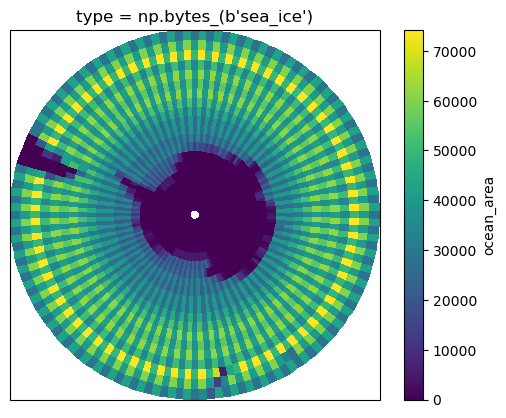

In [35]:
#(t): How much of each 2.5° cell is ocean (km²): the summed areas of its points with a concentration
example_ocean_area_da = example_grid_sums_ds['ocean_area']
example_ocean_area_da.plot(**POLAR);

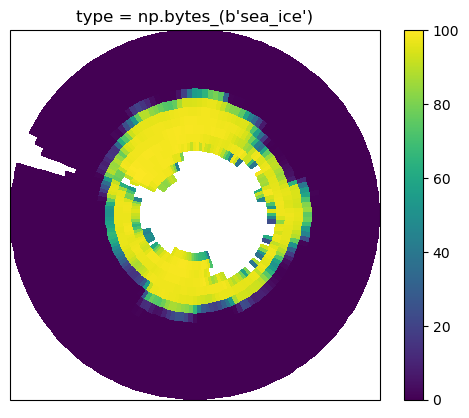

In [36]:
#(t): The mean concentration: the summed area × concentration over the ocean area; empty where a cell has no ocean
example_grid_da = example_grid_sums_ds['weighted_siconc'] / example_ocean_area_da.where(example_ocean_area_da > 0)
example_grid_da.plot(vmin=0, vmax=100, **POLAR);

**How much of each cell is ocean**

A cell's whole area on the sphere is $R^2\,\Delta\lambda\,(\sin\varphi_\text{north} - \sin\varphi_\text{south})$, with its edges half a cell either side of its centre. The same formula gives ERA5's 0.25° cells in section 2.

In [37]:
#(t): The area (km²) of each cell of a regular latitude-longitude grid with this spacing (degrees), from its centres:
#(t): R² Δλ (sin φ_north − sin φ_south), its edges half a spacing either side of its centre (none beyond a pole)
#(c): In float64: ERA5's latitudes are float32, too coarse for the difference of two sines 0.25° apart
def cell_area(lat_da, lon_da, spacing):
    north_da = np.deg2rad(np.minimum(lat_da.astype('float64') + spacing / 2, 90))
    south_da = np.deg2rad(np.maximum(lat_da.astype('float64') - spacing / 2, -90))
    return EARTH_RADIUS ** 2 * np.deg2rad(spacing) * (np.sin(north_da) - np.sin(south_da)) * xr.ones_like(lon_da)

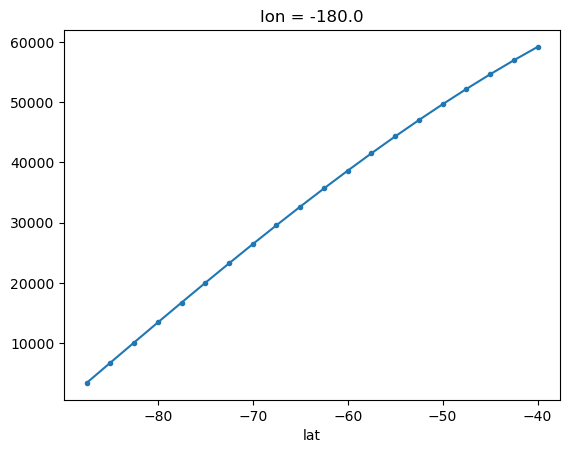

In [38]:
#(t): Each 2.5° cell's whole area (km²), larger towards the equator
grid_lat_da = xr.DataArray(GRID_LAT, dims='lat', coords={'lat': GRID_LAT})
grid_lon_da = xr.DataArray(GRID_LON, dims='lon', coords={'lon': GRID_LON})
grid_cell_area_da = cell_area(grid_lat_da, grid_lon_da, 2.5)
grid_cell_area_da.isel(lon=0).plot(marker='.');

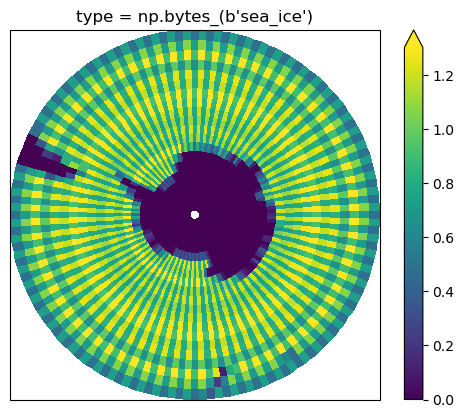

In [39]:
#(t): The ocean's share of each cell: 1 at sea, less on the coast, 0 on the continent
#(c): A share a little over 1 is a cell that got one more row of points than its neighbour
example_ocean_share_da = example_ocean_area_da / grid_cell_area_da
example_ocean_share_da.plot(vmin=0, vmax=1.3, **POLAR);

In [40]:
#(t): Check: the extent (million km²) on the model's own grid, and on the 2.5° grid counting each cell's ocean
example_own_grid_extent = float((example_point_area_da * (example_native_da >= THRESHOLD)).sum()) / 1e6
example_on_grid_extent = float(example_ocean_area_da.where(example_grid_da >= THRESHOLD, 0).sum()) / 1e6
example_own_grid_extent, example_on_grid_extent

(20.003472, 20.950728)

In [41]:
#(t): Saved for 09b's figure of the method
regrid_example_ds = xr.Dataset({'native': example_native_da, 'native_lat': example_native_ds['latitude'], 'native_lon': example_native_ds['longitude'],
                                'on_grid': example_grid_da})

**The same steps as one function**

`onto_grid` does the steps above for one member's concentration on (time, its own grid). Every file in section 2 goes through it.

In [42]:
#(t): The steps above for one member's concentration (%) on (time, its own grid), with each point's area (km²),
#(t): latitude and longitude: its concentration on the 2.5° grid, and each cell's ocean (km²)
def onto_grid(siconc_da, point_area_da, lat_da, lon_da):
    #(c): The centre of the 2.5° cell each point falls in
    cell_lat_da = -87.5 + 2.5 * np.floor((lat_da + 88.75) / 2.5)
    cell_lon_da = -180 + 2.5 * np.floor(((lon_da + 181.25) % 360) / 2.5)
    #(c): Each point's area times its concentration, and its area where it is ocean, labelled with its cell
    points_ds = xr.Dataset({'weighted_siconc': point_area_da * siconc_da,
                            'ocean_area': point_area_da.where(siconc_da.notnull())},
                           coords={'cell_lat': cell_lat_da, 'cell_lon': cell_lon_da})
    #(c): Summed over each cell's points, on the whole grid; 0 in a cell with no point
    sums_ds = points_ds.groupby(['cell_lat', 'cell_lon']).sum()
    named_sums_ds = sums_ds.rename(cell_lat='lat', cell_lon='lon')
    grid_sums_ds = named_sums_ds.reindex(lat=GRID_LAT, lon=GRID_LON).fillna(0)
    #(c): The mean; the ocean is the same every month (land has no value in any), so the first month's is kept
    siconc_grid_da = grid_sums_ds['weighted_siconc'] / grid_sums_ds['ocean_area'].where(grid_sums_ds['ocean_area'] > 0)
    ocean_area_da = grid_sums_ds['ocean_area'].isel(time=0, drop=True)
    #(c): Only time, lat and lon kept as coordinates (not the file's label, type)
    return xr.Dataset({'siconc': siconc_grid_da, 'ocean_area': ocean_area_da}).reset_coords(drop=True)

In [43]:
#(t): Check: the function gives the same September 2013 as the steps above (largest difference, %)
example_function_ds = onto_grid(example_native_ds['siconc'], example_point_area_da, example_native_ds['latitude'], example_native_ds['longitude'])
float(abs(example_function_ds['siconc'].sel(time='2013-09').squeeze('time', drop=True) - example_grid_da).max())

0.0

## 2. The data on the 2.5° grid

Run **one** of the next two sections. Both leave `ice_monthly_tree` (/<model>/<experiment>: `siconc` in % on member × time × lat × lon, and `ocean_area` in km² on lat × lon), `era5_ice_ds` (ERA5's `siconc` and `ocean_area`), and `RUN`.

Every model's file goes through section 1's `onto_grid`. GISS-E2-1-G is the one different model: its files are `siconca`, the concentration on its atmosphere grid. That grid is regular, so its positions are 1-D `lat` and `lon`; and `siconca` is 0 over land rather than empty, so its land cannot be told from open water, and it takes ERA5's ocean instead.

In [44]:
#(t): One member's sea-ice file(s), opened, onto the 2.5° grid as one member: siconc (%) on (member, time, lat, lon)
#(t): and ocean_area (km²). The member's label is the file's variant_label
@skip_empty
def file_onto_grid(native_ds, area_ds, era5_ocean_area_da):
    #(c): siconc, or GISS-E2-1-G's siconca
    variable = 'siconca' if 'siconca' in native_ds else 'siconc'
    lat_name, lon_name = POSITION_NAMES[variable]
    point_area_da = area_ds[AREA_VARIABLES[variable]] / 1e6
    grid_ds = onto_grid(native_ds[variable], point_area_da, native_ds[lat_name], native_ds[lon_name])
    siconc_da = grid_ds['siconc'].expand_dims(member=[native_ds.attrs['variant_label']])
    if variable == 'siconc':
        return xr.Dataset({'siconc': siconc_da, 'ocean_area': grid_ds['ocean_area']})
    #(c): siconca is 0 over land, so its own ocean is every cell: ERA5's ocean instead, and the cells with none made
    #(c): empty, as an ocean model leaves them
    return xr.Dataset({'siconc': siconc_da.where(era5_ocean_area_da > 0), 'ocean_area': era5_ocean_area_da})

### Sample data

One member of each model and experiment for 2013–2014, and ERA5 at 00 UTC on the 15th of each month (`scripts/sea_ice_sample.py`).

In [45]:
#(t): ERA5's sea-ice cover, on its regular 0.25° grid (1-D latitude and longitude), as a fraction (0-1)
era5_sample_path = paths.SEA_ICE_SAMPLE_DIR / 'era5_ci.nc'
era5_native_ds = xr.open_dataset(era5_sample_path)
era5_native_ds

<xarray.Dataset> Size: 56MB
Dimensions:    (time: 24, latitude: 201, longitude: 1440)
Coordinates:
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
  * latitude   (latitude) float32 804B -40.0 -40.25 -40.5 ... -89.5 -89.75 -90.0
  * time       (time) datetime64[ns] 192B 2013-01-15 2013-02-15 ... 2014-12-15
Data variables:
    siconc     (time, latitude, longitude) float64 56MB ...
Attributes: (2)

In [ ]:
#(t): Each ERA5 point's area (km²): a 0.25° cell
era5_point_area_da = cell_area(era5_native_ds['latitude'], era5_native_ds['longitude'], 0.25)
era5_point_area_da.plot(**POLAR);

In [47]:
#(t): ERA5 on the 2.5° grid (section 1's steps), and each cell's ocean (ERA5 leaves land empty)
era5_grid_ds = onto_grid(era5_native_ds['siconc'], era5_point_area_da, era5_native_ds['latitude'],
                         era5_native_ds['longitude'])
era5_grid_ds

<xarray.Dataset> Size: 578kB
Dimensions:     (time: 24, lat: 20, lon: 144)
Coordinates:
  * time        (time) datetime64[ns] 192B 2013-01-15 2013-02-15 ... 2014-12-15
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (time, lat, lon) float64 553kB nan nan nan nan ... 0.0 0.0 0.0
    ocean_area  (lat, lon) float64 23kB 0.0 0.0 0.0 ... 1.879e+04 3.106e+04

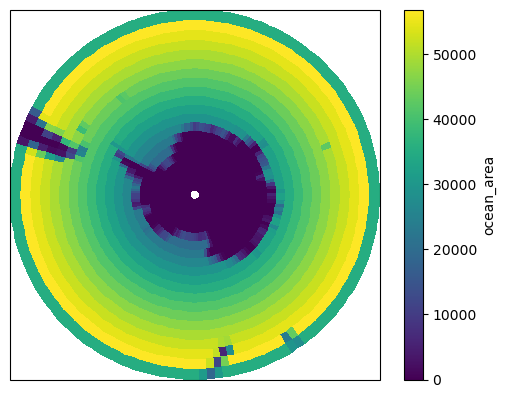

In [48]:
#(t): ERA5's ocean in each cell (km²)
era5_ocean_area_da = era5_grid_ds['ocean_area']
era5_ocean_area_da.plot(**POLAR);

In [49]:
#(t): ERA5's concentration in %, like the models', and its ocean
era5_ice_ds = xr.Dataset({'siconc': 100 * era5_grid_ds['siconc'], 'ocean_area': era5_ocean_area_da})
era5_ice_ds

<xarray.Dataset> Size: 578kB
Dimensions:     (time: 24, lat: 20, lon: 144)
Coordinates:
  * time        (time) datetime64[ns] 192B 2013-01-15 2013-02-15 ... 2014-12-15
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (time, lat, lon) float64 553kB nan nan nan nan ... 0.0 0.0 0.0
    ocean_area  (lat, lon) float64 23kB 0.0 0.0 0.0 ... 1.879e+04 3.106e+04

In [50]:
#(t): The models' files: <model>_<experiment>_<variable>_<member>_<grid>.nc (the cell-area files have fewer parts)
sample_files = sorted(sample_dir.glob('*_*_*_*_*.nc'))
sample_files

[PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-GHG_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-aer_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-nat_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_hist-stratO3_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/CanESM5_historical_siconc_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/GISS-E2-1-G_hist-GHG_siconca_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/GISS-E2-1-G_hist-aer_siconca_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/sea_ice/lesfmip/GISS-E2-1-G_historical_siconca_r1i1p1f1_gn.nc'),
 PosixPath('/home/users/aborow/ExtAnt-initial/tests/data/

In [51]:
#(t): One row per file, its name split into its parts
sample_files_df = pd.DataFrame([dict(zip(['model', 'experiment', 'variable', 'member', 'grid'], path.stem.split('_')),
                                     path=path) for path in sample_files])
sample_files_df

,model,experiment,variable,member,grid,path
0,CanESM5,hist-GHG,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
1,CanESM5,hist-aer,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
2,CanESM5,hist-nat,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
3,CanESM5,hist-stratO3,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
4,CanESM5,historical,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
5,GISS-E2-1-G,hist-GHG,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
6,GISS-E2-1-G,hist-aer,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
7,GISS-E2-1-G,historical,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
8,HadGEM3-GC31-LL,hist-GHG,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...
9,HadGEM3-GC31-LL,hist-aer,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...


In [52]:
#(t): The cell areas of each file's grid: areacello for siconc (the ocean model's), areacella for siconca (the atmosphere's)
sample_files_df['area_path'] = [sample_dir / f'{row.model}_{AREA_VARIABLES[row.variable]}_{row.grid}.nc'
                                for row in sample_files_df.itertuples()]

In [53]:
#(t): hist-stratO3 stands in for hist-totalO3
sample_files_df['experiment'] = sample_files_df['experiment'].replace(OZONE_NAMES)

In [54]:
#(t): One file per model and experiment: siconc (the ocean grid) where a model has both it and siconca
sample_files_df = sample_files_df.sort_values(['model', 'experiment', 'variable']).drop_duplicates(['model', 'experiment'])
sample_files_df

,model,experiment,variable,member,grid,path,area_path
0,CanESM5,hist-GHG,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
1,CanESM5,hist-aer,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
2,CanESM5,hist-nat,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
3,CanESM5,hist-totalO3,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
4,CanESM5,historical,siconc,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
5,GISS-E2-1-G,hist-GHG,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
6,GISS-E2-1-G,hist-aer,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
7,GISS-E2-1-G,historical,siconca,r1i1p1f1,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
8,HadGEM3-GC31-LL,hist-GHG,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...
9,HadGEM3-GC31-LL,hist-aer,siconc,r1i1p1f3,gn,/home/users/aborow/ExtAnt-initial/tests/data/s...,/home/users/aborow/ExtAnt-initial/tests/data/s...


In [55]:
#(t): Each file opened on its model's own grid, /<model>/<experiment>: only its concentration, with its points'
#(t): positions. Most are on (time, j, i); MIROC6's on (time, y, x); GISS-E2-1-G's siconca on (time, lat, lon)
sample_native_tree = xr.DataTree.from_dict({f'{row.model}/{row.experiment}': xr.open_dataset(row.path)[[row.variable]]
                                           for row in sample_files_df.itertuples()})
sample_native_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:    (time: 24, j: 88, i: 360)
│   │       Coordinates:
│   │         * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│   │         * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│   │           latitude   (j, i) float64 253kB ...
│   │           longitude  (j, i) float64 253kB ...
│   │           type       |S7 7B ...
│   │       Data variables:
│   │           siconc     (time, j, i) float32 3MB ...
│   │       Attributes: (53)
│   └── Group: /CanESM5/historical
│           Dimensions:    (time: 24, j: 88, i: 360)
│           Coordinates:
│             * time       (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│             * j          (j) int32 352B 0 1 2 3 4 5 6 7 8 9 ... 79 80 81 82 83 84 85 86 87
│             * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
│               latitude   (j, i) float64 253kB ...
│               longitude  (j, i) float64 253kB ...
│               type       |S7 7B ...
│           Data variables:
│               siconc     (time, j, i) float32 3MB ...
│           Attributes: (53)
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:  (time: 24, lat: 25, lon: 144)
│   │       Coordinates:
│   │         * time     (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat      (lat) float64 200B -89.0 -87.0 -85.0 -83.0 ... -45.0 -43.0 -41.0
│   │         * lon      (lon) float64 1kB 1.25 3.75 6.25 8.75 ... 351.2 353.8 356.2 358.8
│   │           type     |S7 7B ...
│   │       Data variables:
│   │           siconca  (time, lat, lon) float32 346kB ...
│   │       Attributes: (48)
│   ├── Group: /GISS-E2-1-G/hist-aer
│   │       Dimensions:  (time: 24, lat: 25, lon: 144)
│   │       Coordinates:
│   │         * time     (time) object 192B 2013-01-16 12

In [56]:
#(t): Each file's cell areas (m²), in the same places
sample_area_tree = xr.DataTree.from_dict({f'{row.model}/{row.experiment}': xr.open_dataset(row.area_path)
                                         for row in sample_files_df.itertuples()})
sample_area_tree

<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:             (j: 88, i: 360, vertices: 4)
│   │       Coordinates:
│   │         * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│   │         * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│   │           latitude            (j, i) float64 253kB ...
│   │           longitude           (j, i) float64 253kB ...
│   │       Dimensions without coordinates: vertices
│   │       Data variables:
│   │           vertices_latitude   (j, i, vertices) float64 1MB ...
│   │           vertices_longitude  (j, i, vertices) float64 1MB ...
│   │           areacello           (j, i) float32 127kB ...
│   │       Attributes: (52)
│   └── Group: /CanESM5/historical
│           Dimensions:             (j: 88, i: 360, vertices: 4)
│           Coordinates:
│             * j                   (j) int32 352B 0 1 2 3 4 5 6 7 ... 81 82 83 84 85 86 87
│             * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
│               latitude            (j, i) float64 253kB ...
│               longitude           (j, i) float64 253kB ...
│           Dimensions without coordinates: vertices
│           Data variables:
│               vertices_latitude   (j, i, vertices) float64 1MB ...
│               vertices_longitude  (j, i, vertices) float64 1MB ...
│               areacello           (j, i) float32 127kB ...
│           Attributes: (52)
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:    (lat: 25, bnds: 2, lon: 144)
│   │       Coordinates:
│   │         * lat        (lat) float64 200B -89.0 -87.0 -85.0 -83.0 ... -45.0 -43.0 -41.0
│   │         * lon    

In [57]:
%%time
#(t): Every file onto the 2.5° grid (file_onto_grid)
ice_monthly_tree = xr.map_over_datasets(file_onto_grid, sample_native_tree, sample_area_tree, era5_ocean_area_da)
ice_monthly_tree

CPU times: user 1.61 s, sys: 36 ms, total: 1.65 s
Wall time: 1.66 s


<xarray.DataTree>
Group: /
├── Group: /CanESM5
│   ├── Group: /CanESM5/hist-GHG
│   │       Dimensions:     (member: 1, time: 24, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * member      (member) object 8B 'r1i1p1f1'
│   │         * time        (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 276kB nan nan nan ... 0.0 0.0
│   │           ocean_area  (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04
│   ├── Group: /CanESM5/hist-aer
│   │       Dimensions:     (member: 1, time: 24, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * member      (member) object 8B 'r1i1p1f1'
│   │         * time        (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 276kB nan nan nan ... 0.0 0.0
│   │           ocean_area  (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04
│   ├── Group: /CanESM5/hist-nat
│   │       Dimensions:     (member: 1, time: 24, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * member      (member) object 8B 'r1i1p1f1'
│   │         * time        (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 276kB nan nan nan ... 0.0 0.0
│   │           ocean_area  (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04
│   ├── Group: /CanESM5/hist-totalO3
│   │       Dimensions:     (member: 1, time: 24, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * member      (member) object 8B 'r1i1p1f1'
│   │         * time        (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 276kB nan nan nan ... 0.0 0.0
│   │           ocean_area  (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04
│   └── Group: /CanESM5/historical
│           Dimensions:     (member: 1, time: 24, lat: 20, lon: 144)
│           Coordinates:
│             * member      (member) object 8B 'r1i1p1f1'
│             * time        (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│             * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│             * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│           Data variables:
│               siconc      (member, time, lat, lon) float32 276kB nan nan nan ... 0.0 0.0
│               ocean_area  (lat, lon) float32 12kB 0.0 0.0 0.0 ... 2.13e+04 3.556e+04
├── Group: /GISS-E2-1-G
│   ├── Group: /GISS-E2-1-G/hist-GHG
│   │       Dimensions:     (member: 1, time: 24, lat: 20, lon: 144)
│   │       Coordinates:
│   │         * member      (member) object 8B 'r1i1p1f1'
│   │         * time        (time) object 192B 2013-01-16 12:00:00 ... 2014-12-16 12:00:00
│   │         * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
│   │         * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
│   │       Data variables:
│   │           siconc      (member, time, lat, lon) float32 276kB nan nan nan ... 0.0 0.0
│   │           ocean_

In [58]:
RUN = 'sample'

### Full data (JASMIN)

The CEDA files of every member onto the 2.5° grid, saved as one monthly store per model and experiment (once; it skips what is done), and ERA5's daily files to monthly means on the grid.

#### What is on CEDA

In [59]:
#(t): The experiments looked for: notebook 01's, and hist-stratO3
CEDA_EXPERIMENTS = [*EXPERIMENTS, *OZONE_NAMES]
CEDA_EXPERIMENTS

['hist-nat',
 'hist-aer',
 'hist-totalO3',
 'hist-GHG',
 'historical',
 'hist-stratO3']

In [60]:
#(t): Every folder of the sea ice and of the cell areas of these models and experiments (the areas also from
#(t): piControl), in DAMIP, CMIP and CMIP6Plus (convert.ceda_inventory searches paths.CEDA_CMIP6)
ice_inventory_df = convert.ceda_inventory(MODELS, CEDA_EXPERIMENTS)
ice_inventory_df

,project,activity,institution,model,experiment,member,table,variable,grid,n_files,start,end,folder
0,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r1i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
1,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r2i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
2,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r3i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
3,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r4i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
4,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r5i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
466,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r3i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
467,CMIP6,CMIP,NCC,NorESM2-LM,historical,r1i1p1f1,fx,areacella,gn,1,NaN,NaN,/badc/cmip6/data/CMIP6/CMIP/NCC/NorESM2-LM/his...
468,CMIP6,CMIP,NCC,NorESM2-LM,historical,r1i1p1f1,Ofx,areacello,gn,1,NaN,NaN,/badc/cmip6/data/CMIP6/CMIP/NCC/NorESM2-LM/his...
469,CMIP6,CMIP,NCC,NorESM2-LM,historical,r1i1p1f1,SImon,siconc,gn,17,1850.0,2014.0,/badc/cmip6/data/CMIP6/CMIP/NCC/NorESM2-LM/his...


In [61]:
#(t): The members used: CMIP6 only (CMIP6Plus's f2023 members have other forcing), monthly sea ice (SImon)
ice_members_df = ice_inventory_df.query('table == "SImon" and project == "CMIP6"')

In [62]:
#(t): siconc where a model has it for an experiment, else siconca ('siconc' sorts first, so it is the minimum)
ice_members_df = ice_members_df[ice_members_df['variable']
                                == ice_members_df.groupby(['model', 'experiment'])['variable'].transform('min')]

In [63]:
#(t): Only members that cover 1850 to the end of historical
ice_members_df = ice_members_df.query('start <= 1850 and end >= 2014')
ice_members_df

,project,activity,institution,model,experiment,member,table,variable,grid,n_files,start,end,folder
0,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r1i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
1,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r2i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
2,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r3i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
3,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r4i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
4,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r5i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
...,...,...,...,...,...,...,...,...,...,...,...,...,...
463,CMIP6,DAMIP,NCC,NorESM2-LM,hist-aer,r3i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
464,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r1i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
465,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r2i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...
466,CMIP6,DAMIP,NCC,NorESM2-LM,hist-nat,r3i1p1f1,SImon,siconc,gn,18,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/NCC/NorESM2-LM/hi...


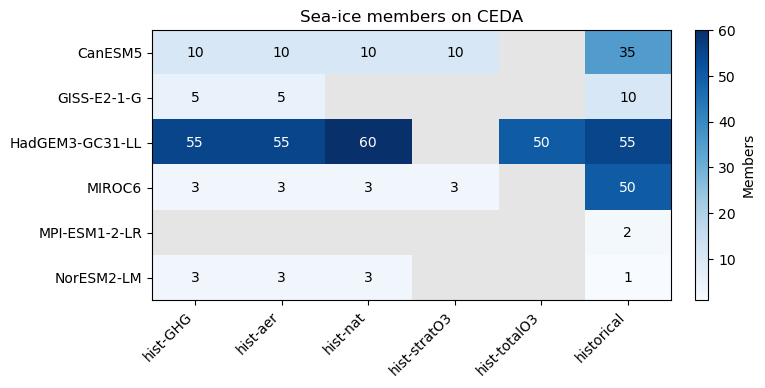

In [64]:
#(t): Members on CEDA per model and experiment
ceda_member_counts_df = ice_members_df.pivot_table(index='model', columns='experiment', values='member', aggfunc='nunique')
fig, ax = methods.member_count_heatmap(ceda_member_counts_df, title='Sea-ice members on CEDA')

#### ERA5: daily values to monthly means (JASMIN)

ERA5's sea ice comes from satellite analyses once a day, so the 00 UTC field is the day's: each month's mean is of about 30 files. Each month is averaged on a worker, put on the 2.5° grid in %, and each year saved as a store, then joined, as in notebook 01, section 2.

In [65]:
#(t): One day's file, for the grid and the land
era5_day_path = convert.era5_files('siconc', 1979, 1, hour=0)[0]
era5_day_path

PosixPath('/badc/ecmwf-era5/data/oper/an_sfc/1979/01/01/ecmwf-era5_oper_an_sfc_197901010000.ci.nc')

In [66]:
#(t): Only south of the grid's edge
era5_day_ds = convert.era5_south(xr.open_dataset(era5_day_path))
era5_day_ds

<xarray.Dataset> Size: 2MB
Dimensions:    (longitude: 1440, latitude: 209, time: 1)
Coordinates:
  * longitude  (longitude) float32 6kB 0.0 0.25 0.5 0.75 ... 359.2 359.5 359.8
  * latitude   (latitude) float32 836B -90.0 -89.75 -89.5 ... -38.5 -38.25 -38.0
  * time       (time) datetime64[ns] 8B 1979-01-01
Data variables:
    siconc     (time, latitude, longitude) float64 2MB ...
Attributes: (2)

In [67]:
#(t): Each ERA5 point's area (km²): a 0.25° cell
era5_point_area_da = cell_area(era5_day_ds['latitude'], era5_day_ds['longitude'], 0.25)

In [68]:
#(t): The day on the 2.5° grid (section 1's steps), for each cell's ocean: the points with a value (ERA5's sea-ice
#(t): variable is siconc in the files)
era5_day_grid_ds = onto_grid(era5_day_ds['siconc'], era5_point_area_da, era5_day_ds['latitude'], era5_day_ds['longitude'])
era5_day_grid_ds

<xarray.Dataset> Size: 47kB
Dimensions:     (time: 1, lat: 20, lon: 144)
Coordinates:
  * time        (time) datetime64[ns] 8B 1979-01-01
  * lat         (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * lon         (lon) float64 1kB -180.0 -177.5 -175.0 ... 172.5 175.0 177.5
Data variables:
    siconc      (time, lat, lon) float64 23kB nan nan nan nan ... 0.0 0.0 0.0
    ocean_area  (lat, lon) float64 23kB 0.0 0.0 0.0 ... 2.476e+04 4.359e+04

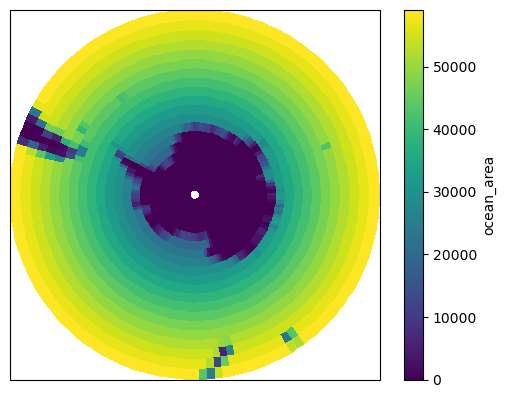

In [69]:
#(t): Each cell's ocean (km²)
era5_ocean_area_da = era5_day_grid_ds['ocean_area']
era5_ocean_area_da.plot(**POLAR);

In [70]:
#(t): Years already done: saved as a year store (an interrupted run), or in the joined store
era5_years_dir = paths.era5_years_dir('siconc')
era5_done_years = [int(store.stem) for store in paths.find_all(era5_years_dir, '*.zarr')]
if storage.exists(paths.era5_monthly('siconc')):
    era5_done_years += np.unique(storage.open_dataarray(paths.era5_monthly('siconc')).time.dt.year).tolist()
era5_done_years

14:56:50 INFO    extant.storage | opening /work/scratch-pw4/aborow/ExtAnt/monthly/era5_siconc.zarr


[1979,
 1980,
 1981,
 1982,
 1983,
 1984,
 1985,
 1986,
 1987,
 1988,
 1989,
 1990,
 1991,
 1992,
 1993,
 1994,
 1995,
 1996,
 1997,
 1998,
 1999,
 2000,
 2001,
 2002,
 2003,
 2004,
 2005,
 2006,
 2007,
 2008,
 2009,
 2010,
 2011,
 2012,
 2013,
 2014]

In [71]:
#(t): The years left, up to the end of historical
era5_todo_years = [year for year in range(1979, 2015) if year not in era5_done_years]
era5_todo_years

[]

In [72]:
%%time
#(t): Every month on the workers; each year onto the grid (onto_grid), in %, and saved as soon as its twelve months
#(t): are back
era5_futures = {year: [client.submit(convert.era5_month_mean, convert.era5_files('siconc', year, month, hour=0),
                                     'siconc', pure=False) for month in range(1, 13)]
                for year in era5_todo_years}
for year in era5_todo_years:
    year_da = xr.DataArray(np.stack(client.gather(era5_futures[year])), dims=('time', 'latitude', 'longitude'),
                           coords={'time': pd.date_range(f'{year}-01-01', periods=12, freq='MS'),
                                   'latitude': era5_day_ds['latitude'], 'longitude': era5_day_ds['longitude']})
    year_grid_ds = onto_grid(year_da, era5_point_area_da, era5_day_ds['latitude'], era5_day_ds['longitude'])
    year_grid_da = 100 * year_grid_ds['siconc']
    storage.save(year_grid_da.astype('float32').rename('siconc'), era5_years_dir / f'{year}.zarr')

CPU times: user 0 ns, sys: 7 μs, total: 7 μs
Wall time: 12.6 μs


In [73]:
#(t): The year stores joined into one store, and deleted
era5_monthly_da = convert.combine_era5_years('siconc')
era5_monthly_da

14:56:50 INFO    extant.storage | opening /work/scratch-pw4/aborow/ExtAnt/monthly/era5_siconc.zarr
14:56:50 INFO    extant.storage | writing DataArray (time: 432, lat: 20, lon: 144) to /work/scratch-pw4/aborow/ExtAnt/monthly/era5_siconc.zarr
14:56:51 INFO    extant.storage | saved /work/scratch-pw4/aborow/ExtAnt/monthly/era5_siconc.zarr
14:56:51 INFO    extant.convert | ERA5 siconc: {'time': 432, 'lat': 20, 'lon': 144} saved, 0 year stores removed


/apps/jasmin/jaspy/miniforge_envs/jaspy3.12/mf3-25.3.0-3/envs/jaspy3.12-mf3-25.3.0-3-v20250704/lib/python3.12/site-packages/zarr/api/asynchronous.py:227: UserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(


<xarray.DataArray 'siconc' (time: 432, lat: 20, lon: 144)> Size: 5MB
nan nan nan nan nan nan nan nan nan nan ... 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0 0.0
Coordinates:
  * lon      (lon) float64 1kB -180.0 -177.5 -175.0 -172.5 ... 172.5 175.0 177.5
  * lat      (lat) float64 160B -87.5 -85.0 -82.5 -80.0 ... -45.0 -42.5 -40.0
  * time     (time) datetime64[ns] 3kB 1979-01-01 1979-02-01 ... 2014-12-01

#### The models: one store, step by step (JASMIN)

What the loop below does for each store, on the first model and experiment. Nothing is saved here.

In [74]:
#(t): One row per model and experiment: its variable and grid, and the store it goes to (hist-stratO3 saved as
#(t): hist-totalO3, under the names of notebook 01's stores)
ice_stores_df = ice_members_df.drop_duplicates(['model', 'experiment'])[['model', 'experiment', 'variable', 'grid']]
ice_stores_df['store'] = [paths.lesfmip_monthly(row.model, 'siconc', OZONE_NAMES.get(row.experiment, row.experiment),
                                                'interp') for row in ice_stores_df.itertuples()]
ice_stores_df

,model,experiment,variable,grid,store
0,CanESM5,hist-GHG,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ca...
10,CanESM5,hist-aer,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ca...
20,CanESM5,hist-nat,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ca...
30,CanESM5,hist-stratO3,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ca...
42,CanESM5,historical,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ca...
79,GISS-E2-1-G,hist-GHG,siconca,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/GI...
84,GISS-E2-1-G,hist-aer,siconca,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/GI...
89,GISS-E2-1-G,historical,siconca,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/GI...
101,HadGEM3-GC31-LL,hist-GHG,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ha...
156,HadGEM3-GC31-LL,hist-aer,siconc,gn,/work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ha...


In [75]:
first_store = ice_stores_df.iloc[0]
first_store

model                                                   CanESM5
experiment                                             hist-GHG
variable                                                 siconc
grid                                                         gn
store         /work/scratch-pw4/aborow/LESFMIP/monthly_v2/Ca...
Name: 0, dtype: object

In [76]:
#(t): Its members' rows in the inventory
first_rows_df = ice_members_df.query('model == @first_store.model and experiment == @first_store.experiment')
first_rows_df

,project,activity,institution,model,experiment,member,table,variable,grid,n_files,start,end,folder
0,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r1i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
1,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r2i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
2,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r3i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
3,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r4i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
4,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r5i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
5,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r6i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
6,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r7i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
7,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r8i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
8,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r9i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...
9,CMIP6,DAMIP,CCCma,CanESM5,hist-GHG,r10i1p1f1,SImon,siconc,gn,1,1850.0,2020.0,/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/his...


In [77]:
#(t): Each member's files (a member's record can be split over several files)
first_member_files = {row.member: sorted(Path(row.folder).glob('*.nc')) for row in first_rows_df.itertuples()}
first_member_files

{'r1i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r1i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r1i1p1f1_gn_185001-202012.nc')],
 'r2i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r2i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r2i1p1f1_gn_185001-202012.nc')],
 'r3i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r3i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r3i1p1f1_gn_185001-202012.nc')],
 'r4i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r4i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r4i1p1f1_gn_185001-202012.nc')],
 'r5i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r5i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r5i1p1f1_gn_185001-202012.nc')],
 'r6i1p1f1': [PosixPath('/badc/cmip6/data/CMIP6/DAMIP/CCCma/CanESM5/hist-GHG/r6i1p1f1/SImon/siconc/gn/latest/siconc_SImon_CanESM5_hist-GHG_r

In [78]:
#(t): The file of the cell areas of its grid (convert.ceda_area_file: the first run that has them)
first_area_path = convert.ceda_area_file(ice_inventory_df, first_store.model, AREA_VARIABLES[first_store.variable],
                                         first_store.grid)
first_area_path

PosixPath('/badc/cmip6/data/CMIP6/CMIP/CCCma/CanESM5/historical/r1i1p1f1/Ofx/areacello/gn/latest/areacello_Ofx_CanESM5_historical_r1i1p1f1_gn.nc')

In [79]:
first_area_ds = xr.open_dataset(first_area_path)
first_area_ds

<xarray.Dataset> Size: 9MB
Dimensions:             (j: 291, i: 360, vertices: 4)
Coordinates:
  * j                   (j) int32 1kB 0 1 2 3 4 5 6 ... 285 286 287 288 289 290
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 838kB ...
    longitude           (j, i) float64 838kB ...
Dimensions without coordinates: vertices
Data variables:
    vertices_latitude   (j, i, vertices) float64 3MB ...
    vertices_longitude  (j, i, vertices) float64 3MB ...
    areacello           (j, i) float32 419kB ...
Attributes: (52)

In [80]:
#(t): The first member's files, opened together (lazily)
first_member, first_files = next(iter(first_member_files.items()))
first_member_ds = xr.open_mfdataset(first_files, combine='by_coords', data_vars='minimal', coords='minimal',
                                    compat='override')
first_member_ds

<xarray.Dataset> Size: 868MB
Dimensions:             (time: 2052, bnds: 2, j: 291, i: 360, vertices: 4)
Coordinates:
  * time                (time) object 16kB 1850-01-16 12:00:00 ... 2020-12-16...
  * j                   (j) int32 1kB 0 1 2 3 4 5 6 ... 285 286 287 288 289 290
  * i                   (i) int32 1kB 0 1 2 3 4 5 6 ... 354 355 356 357 358 359
    latitude            (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    longitude           (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    type                |S7 7B ...
Dimensions without coordinates: bnds, vertices
Data variables:
    time_bnds           (time, bnds) object 33kB dask.array<chunksize=(1, 2), meta=np.ndarray>
    vertices_latitude   (j, i, vertices) float64 3MB dask.array<chunksize=(291, 360, 2), meta=np.ndarray>
    vertices_longitude  (j, i, vertices) float64 3MB dask.array<chunksize=(291, 360, 2), meta=np.ndarray>
    siconc              (time, j, i) float32 860MB dask.array<chunksize=(1, 291, 360), meta=np.ndarray>
Attributes: (53)

In [81]:
#(t): Only its sea ice, up to LAST_MONTH
first_siconc_ds = first_member_ds[[first_store.variable]].sel(time=slice(None, LAST_MONTH))
first_siconc_ds

<xarray.Dataset> Size: 831MB
Dimensions:    (time: 1980, j: 291, i: 360)
Coordinates:
  * time       (time) object 16kB 1850-01-16 12:00:00 ... 2014-12-16 12:00:00
  * j          (j) int32 1kB 0 1 2 3 4 5 6 7 ... 283 284 285 286 287 288 289 290
  * i          (i) int32 1kB 0 1 2 3 4 5 6 7 ... 352 353 354 355 356 357 358 359
    latitude   (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    longitude  (j, i) float64 838kB dask.array<chunksize=(291, 360), meta=np.ndarray>
    type       |S7 7B ...
Data variables:
    siconc     (time, j, i) float32 830MB dask.array<chunksize=(1, 291, 360), meta=np.ndarray>
Attributes: (53)

In [82]:
#(t): Only the points south of the grid's northern edge (38.75°S), read into memory (the files are global)
first_lat_name, first_lon_name = POSITION_NAMES[first_store.variable]
first_south_ds = first_siconc_ds.where(first_siconc_ds[first_lat_name] < -38.75, drop=True).load()
first_south_ds

KeyError: 'Indexing with a boolean dask array is not allowed. This will result in a dask array of unknown shape. Such arrays are unsupported by Xarray.Please compute the indexer first using .compute()'

In [ ]:
#(t): Quick look: its September 2000 on the model's own grid
first_south_ds[first_store.variable].sel(time='2000-09').squeeze('time').plot(vmin=0, vmax=100);

In [ ]:
%%time
#(t): The member on the 2.5° grid (file_onto_grid): what every member of every store below goes through
first_grid_ds = file_onto_grid(first_south_ds, first_area_ds, era5_ocean_area_da)
first_grid_ds

In [ ]:
#(t): Quick look: its September 2000 on the 2.5° grid
first_grid_ds['siconc'].isel(member=0).sel(time='2000-09').squeeze('time').plot(vmin=0, vmax=100, **POLAR);

#### The models: every store (JASMIN)

Every store not made yet, one after the other: each member as in the steps above, one at a time, then the members side by side. If one fails, the loop stops with its error; save that one by hand without its broken members (as notebook 01, section 1 says) and run the loop again.

In [ ]:
#(t): Those not made yet
ice_todo_df = ice_stores_df[[not storage.exists(store) for store in ice_stores_df['store']]]
ice_todo_df

In [ ]:
%%time
#(t): Each member as above; then the members along member (ocean_area once: it is the same for every member), saved
for store in ice_todo_df.itertuples():
    rows_df = ice_members_df.query('model == @store.model and experiment == @store.experiment')
    area_path = convert.ceda_area_file(ice_inventory_df, store.model, AREA_VARIABLES[store.variable], store.grid)
    area_ds = xr.open_dataset(area_path)
    lat_name, lon_name = POSITION_NAMES[store.variable]
    member_grid_list = []
    for row in rows_df.itertuples():
        member_ds = xr.open_mfdataset(sorted(Path(row.folder).glob('*.nc')), combine='by_coords', data_vars='minimal',
                                      coords='minimal', compat='override')
        siconc_ds = member_ds[[store.variable]].sel(time=slice(None, LAST_MONTH))
        south_ds = siconc_ds.where(siconc_ds[lat_name] < -38.75, drop=True).load()
        member_grid_list.append(file_onto_grid(south_ds, area_ds, era5_ocean_area_da))
    store_ds = xr.concat(member_grid_list, dim='member', data_vars='minimal', coords='minimal', compat='override',
                         join='override')
    storage.save(store_ds.chunk(member=5), store.store, consolidated=True)

#### Open the stores (JASMIN)

First the file names, then each file opened.

In [ ]:
#(t): Where every model and experiment's monthly store would be
ice_files_df = pd.DataFrame([{'model': model, 'experiment': experiment,
                              'store': paths.lesfmip_monthly(model, 'siconc', experiment, 'interp')}
                             for model in MODELS for experiment in EXPERIMENTS])
ice_files_df

In [ ]:
#(t): Which of them exist (in DATA_DIR or SCRATCH)
ice_files_df['exists'] = [storage.exists(store) for store in ice_files_df['store']]
ice_files_df.pivot(index='model', columns='experiment', values='exists')

In [ ]:
#(t): The full path of each one that exists (DATA_DIR first, then SCRATCH)
ice_found_df = ice_files_df[ice_files_df['exists']].copy()
ice_found_df['path'] = [paths.find(store) for store in ice_found_df['store']]
list(ice_found_df['path'])

In [ ]:
#(t): Each store opened (lazily), named /<model>/<experiment>
ice_monthly_datasets = {f'{row.model}/{row.experiment}': xr.open_zarr(row.path, consolidated=True)
                        for row in ice_found_df.itertuples()}
ice_monthly_tree = xr.DataTree.from_dict(ice_monthly_datasets)
ice_monthly_tree

In [ ]:
#(t): ERA5's monthly store, and its file
era5_monthly_path = paths.find(paths.era5_monthly('siconc'))
era5_monthly_path

In [ ]:
#(t): ERA5, with each cell's ocean
era5_monthly_ds = xr.open_zarr(era5_monthly_path)
era5_ice_ds = xr.Dataset({'siconc': era5_monthly_ds['siconc'].load(), 'ocean_area': era5_ocean_area_da})
era5_ice_ds

In [ ]:
RUN = 'full'

### What was opened

Whichever section ran. First how many members each model has for each experiment: an empty square is a store that was never opened.

In [ ]:
#(t): Members per model (rows) and experiment (columns)
ice_member_counts_df = pd.Series({(node.parent.name, node.name): node.sizes['member']
                                  for node in ice_monthly_tree.leaves}).unstack()
ice_member_counts_df = ice_member_counts_df.reindex(index=MODELS, columns=EXPERIMENTS)
fig, ax = methods.member_count_heatmap(ice_member_counts_df, title='Sea-ice members opened')

In [ ]:
#(t): Quick look: every model's first historical member in September 2013
fig, axes = plt.subplots(1, len(MODELS), figsize=(3 * len(MODELS), 3.2),
                         subplot_kw=dict(projection=ccrs.SouthPolarStereo()))
for ax, model in zip(axes, MODELS):
    if model in ice_monthly_tree.children and 'historical' in ice_monthly_tree[model].children:
        field_da = ice_monthly_tree[model]['historical']['siconc'].isel(member=0).sel(time='2013-09').squeeze('time')
        field_da.plot(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=100, add_colorbar=False)
    ax.set_title(model, fontsize=9)

In [ ]:
#(t): ... and ERA5's
era5_ice_ds['siconc'].sel(time='2013-09').squeeze('time').plot(vmin=0, vmax=100, **POLAR);

In [ ]:
#(t): Section 1's example, for 09b's figure of the method
storage.save(regrid_example_ds, paths.result('regrid_example', 'siconc', RUN))

In [ ]:
#(t): Quick look: MODEL's historical members at one cell near the ice edge, every month
point_da = ice_monthly_tree[MODEL]['historical']['siconc'].sel(lat=-62.5, lon=-150)
point_da.plot.line(x='time', hue='member', add_legend=False, lw=0.6)
point_da.mean('member').plot.line(x='time', color='k', lw=2);

## 3. Seasonal means

Each record is cut at `LAST_MONTH`, then averaged into seasons by `pp.seasonal_means`: DJF is labelled by the year of its December, and only complete seasons in whole years are kept, as for the temperature in notebook 01.

In [ ]:
#(t): Every record cut where historical ends
ice_monthly_cut_tree = ice_monthly_tree.sel(time=slice(None, LAST_MONTH))

In [ ]:
#(t): Every member's seasonal means (%), on (member, year, season, lat, lon), lazily
ice_season_tree = xr.DataTree.from_dict({node.path: xr.Dataset({'siconc': pp.seasonal_means(node['siconc'])})
                                         for node in ice_monthly_cut_tree.leaves})
ice_season_tree

In [ ]:
#(t): Quick look: MODEL's historical members at one cell near the ice edge in JJA (black: their mean)
point_jja_da = ice_season_tree[MODEL]['historical']['siconc'].sel(season='JJA').sel(lat=-62.5, lon=-150)
point_jja_da.plot.line(x='year', hue='member', add_legend=False, lw=0.6)
point_jja_da.mean('member').plot.line(x='year', color='k', lw=2, marker='o');

In [ ]:
#(t): Quick look: four of MODEL's historical members in JJA of the last year
ice_season_tree[MODEL]['historical']['siconc'].isel(year=-1, member=slice(0, 4)).sel(season='JJA').plot(
    col='member', vmin=0, vmax=100, **POLAR);

In [ ]:
#(t): Quick look: a map and the time series behind it. MODEL's first historical member in JJA: the last year's map
#(t): with one cell marked, and every year at that cell
jja_da = ice_season_tree[MODEL]['historical']['siconc'].isel(member=0).sel(season='JJA')
fig = plt.figure(figsize=(12, 4))
ax_map = fig.add_subplot(1, 2, 1, projection=ccrs.SouthPolarStereo())
jja_da.isel(year=-1).plot(ax=ax_map, transform=ccrs.PlateCarree(), vmin=0, vmax=100)
ax_map.plot(-150, -62.5, 'rx', ms=10, mew=2, transform=ccrs.PlateCarree())
ax_series = fig.add_subplot(1, 2, 2)
jja_da.sel(lat=-62.5, lon=-150).plot.line(ax=ax_series, x='year', color='r', marker='o');

## 4. The sea-ice extent and the ice edge

The **extent** is the ocean area of the cells with at least 15% ice. On the 2.5° grid a coastal cell is part land, so each cell counts only its ocean (`ocean_area`, from section 1); the rest of the cells south of 60°S is the continent.

First on one field, step by step.

In [ ]:
#(t): One field: MODEL's first historical member in September 2013 (%)
example_siconc_da = ice_monthly_tree[MODEL]['historical']['siconc'].isel(member=0).sel(time='2013-09')
example_siconc_da = example_siconc_da.squeeze('time', drop=True).load()
example_siconc_da.plot(vmin=0, vmax=100, **POLAR);

In [ ]:
#(t): The cells that count as ice: at least THRESHOLD (15%)
example_ice_cells_da = example_siconc_da >= THRESHOLD
example_ice_cells_da.plot(**POLAR);

In [ ]:
#(t): Each cell's ocean (km²), saved with the store
example_ocean_area_da = ice_monthly_tree[MODEL]['historical']['ocean_area'].load()
example_ocean_area_da.plot(**POLAR);

In [ ]:
#(t): The ice-covered ocean of each cell (km²): its ocean where it is ice, 0 elsewhere
example_ice_area_da = example_ocean_area_da.where(example_ice_cells_da, 0)
example_ice_area_da.plot(**POLAR);

In [ ]:
#(t): The extent: their sum (million km²)
example_extent = float(example_ice_area_da.sum()) / 1e6
example_extent

In [ ]:
#(t): Each 2.5° cell's whole area (km², section 1), the same for every model and ERA5
grid_cell_area_da.plot(**POLAR);

In [ ]:
#(t): The land in each cell (km²): its area less its ocean
example_land_area_da = grid_cell_area_da - example_ocean_area_da
example_land_area_da.plot(**POLAR);

In [ ]:
#(t): The continent (million km²): the land south of 60°S (islands further north are not part of the ice edge)
example_continent_area = float(example_land_area_da.where(example_land_area_da['lat'] <= -60).sum()) / 1e6
example_continent_area

The same steps for every member and month of every model and experiment.

In [ ]:
#(t): One node's extent (km²) every member and month, and its continent (km²): the steps above
@skip_empty
def monthly_extent(ds):
    ice_cells_da = ds['siconc'] >= THRESHOLD
    ice_area_da = ds['ocean_area'].where(ice_cells_da, 0)
    extent_da = ice_area_da.sum(['lat', 'lon'])
    land_area_da = grid_cell_area_da - ds['ocean_area']
    continent_area_da = land_area_da.where(land_area_da['lat'] <= -60).sum(['lat', 'lon'])
    return xr.Dataset({'extent': extent_da, 'continent_area': continent_area_da})

In [ ]:
%%time
#(t): Every model and experiment
ice_monthly_extent_tree = ice_monthly_tree.map_over_datasets(monthly_extent).compute()
ice_monthly_extent_tree

In [ ]:
#(t): Check: the same as the one field above (million km²)
float(ice_monthly_extent_tree[MODEL]['historical']['extent'].isel(member=0).sel(time='2013-09').squeeze()) / 1e6, example_extent

In [ ]:
#(t): Quick look: MODEL's historical members' extent, every month (million km²)
(ice_monthly_extent_tree[MODEL]['historical']['extent'] / 1e6).plot.line(x='time', hue='member', add_legend=False, lw=0.5);

In [ ]:
#(t): Quick look: every model's continent (million km²; the grids' coasts differ a little)
continent_area_ds = tree_to_dataset(ice_monthly_extent_tree.isel(member=0, time=0, drop=True),
                                    dims=['model', 'experiment'])
(continent_area_ds['continent_area'] / 1e6).to_pandas().plot.bar(rot=45, ylabel='million km²');

### Seasonal means of the extent

In [ ]:
#(t): Every record cut where historical ends
ice_monthly_extent_cut_tree = ice_monthly_extent_tree.sel(time=slice(None, LAST_MONTH))

In [ ]:
#(t): Every member's monthly extent averaged into seasons (as the concentration in section 3), on (member, year, season),
#(t): and its model's continent (km²)
ice_extents_tree = xr.DataTree.from_dict({node.path: xr.Dataset({'extent': pp.seasonal_means(node['extent']),
                                                                 'continent_area': node['continent_area']})
                                          for node in ice_monthly_extent_cut_tree.leaves})
ice_extents_tree

In [ ]:
#(t): Quick look: MODEL's first historical member, every season (million km²)
(ice_extents_tree[MODEL]['historical']['extent'].isel(member=0) / 1e6).plot.line(x='year', hue='season');

In [ ]:
storage.save(ice_extents_tree, paths.result('extent', 'siconc', RUN))

### The ice edge on the maps

The 15% line of the ensemble-mean concentration over each experiment's final `WINDOW` years.

In [ ]:
#(t): Each experiment's final WINDOW years of seasonal concentration
ice_final_season_tree = ice_season_tree.isel(year=slice(-WINDOW, None))

In [ ]:
#(t): The ensemble mean over them (%)
ice_final_mean_tree = ice_final_season_tree.mean(['year', 'member'])

In [ ]:
%%time
#(t): In one DataArray, on (model, experiment, season, lat, lon)
ice_climatology_ds = tree_to_dataset(ice_final_mean_tree, dims=['model', 'experiment']).compute()
ice_climatology_da = ice_climatology_ds['siconc'].transpose('model', 'experiment', ...)
ice_climatology_da

In [ ]:
#(t): Quick look: hist-nat's, every model and season
ice_climatology_da.sel(experiment='hist-nat', season=SEASONS).plot(row='model', col='season', vmin=0, vmax=100, **POLAR);

In [ ]:
storage.save(ice_climatology_da.rename('siconc'), paths.result('climatology', 'siconc', RUN))

In [ ]:
#(t): Each cell's ocean, every model and experiment, on (model, experiment, lat, lon), for 09b's figure of the edge
ocean_area_ds = tree_to_dataset(ice_monthly_tree.isel(member=0, time=0, drop=True),
                                dims=['model', 'experiment'])[['ocean_area']]
ocean_area_ds

In [ ]:
storage.save(ocean_area_ds, paths.result('ocean_area', 'siconc', RUN))

### The ice edge as a latitude

On a zonal mean the edge is an **equivalent latitude** (Bracegirdle et al., 2024): the latitude whose polar cap holds the extent and the continent together. The cap south of latitude φ has area 2πR²(1 + sin φ), so φ = arcsin(area / 2πR² − 1).

In [ ]:
#(t): Each member's extent over each experiment's final WINDOW years
ice_final_extents_tree = ice_extents_tree.isel(year=slice(-WINDOW, None))

In [ ]:
#(t): Their ensemble mean (km²), and each model's continent
ice_final_mean_extent_tree = ice_final_extents_tree.mean(['member', 'year'])

In [ ]:
#(t): In one Dataset, on (model, experiment, season)
ice_final_ds = tree_to_dataset(ice_final_mean_extent_tree, dims=['model', 'experiment'])
ice_final_ds

In [ ]:
#(t): The area of the cap: the extent and the continent (km²)
ice_cap_area_da = ice_final_ds['extent'] + ice_final_ds['continent_area']

In [ ]:
#(t): The latitude whose cap has that area (degrees)
hemisphere_area = 2 * np.pi * EARTH_RADIUS ** 2
ice_edges_da = np.rad2deg(np.arcsin(ice_cap_area_da / hemisphere_area - 1))
ice_edges_da

In [ ]:
#(t): Quick look: each model's edge in each experiment
ice_edges_da.sel(season=SEASONS).plot.line(x='season', hue='experiment', col='model', marker='o');

In [ ]:
storage.save(ice_edges_da.rename('edge_latitude'), paths.result('edge_latitude', 'siconc', RUN))

## 5. ERA5, and each model's historical over the same years

ERA5 counted the same way, and each model's historical members over `ERA5_YEARS`, for 09b's comparisons: the seasonal cycle, the concentration and where the edge is.

In [ ]:
%%time
#(t): ERA5's monthly extent (km²) and its continent: the function of section 4
era5_monthly_extent_ds = monthly_extent(era5_ice_ds)
era5_monthly_extent_ds

In [ ]:
#(t): Its seasonal means, and its continent (km²)
era5_extent_ds = xr.Dataset({'extent': pp.seasonal_means(era5_monthly_extent_ds['extent']),
                             'continent_area': era5_monthly_extent_ds['continent_area']})
era5_extent_ds

In [ ]:
storage.save(era5_extent_ds, paths.result('era5_extent', 'siconc', RUN))

### The seasonal cycle

In [ ]:
#(t): Each historical member's monthly extent over ERA5_YEARS
historical_monthly_extent_tree = ice_monthly_extent_tree.match('*/historical').sel(
    time=slice(str(ERA5_YEARS.start), str(ERA5_YEARS.stop)))

In [ ]:
#(t): Its seasonal cycle: the mean extent in each calendar month (million km²), on (member, month)
historical_cycle_tree = xr.DataTree.from_dict({node.path: xr.Dataset({'extent': node['extent'].groupby('time.month').mean() / 1e6})
                                               for node in historical_monthly_extent_tree.leaves})
historical_cycle_tree

In [ ]:
#(t): ERA5's, over the same years
era5_years_extent_da = era5_monthly_extent_ds['extent'].sel(time=slice(str(ERA5_YEARS.start), str(ERA5_YEARS.stop)))
era5_cycle_ds = xr.Dataset({'extent': era5_years_extent_da.groupby('time.month').mean() / 1e6})
era5_cycle_ds

In [ ]:
#(t): Quick look: MODEL's members (grey) and ERA5 (black)
historical_cycle_tree[MODEL]['historical']['extent'].plot.line(x='month', hue='member', add_legend=False, color='0.6')
era5_cycle_ds['extent'].plot(color='k', lw=2);

In [ ]:
storage.save(historical_cycle_tree, paths.result('historical_cycle', 'siconc', RUN))

In [ ]:
storage.save(era5_cycle_ds, paths.result('era5_cycle', 'siconc', RUN))

### The concentration over ERA5_YEARS

In [ ]:
#(t): Each model's historical concentration over ERA5_YEARS
historical_ice_tree = ice_season_tree.match('*/historical').sel(year=ERA5_YEARS)

In [ ]:
#(t): Its ensemble mean (%)
historical_ice_mean_tree = historical_ice_tree.mean(['year', 'member'])

In [ ]:
%%time
#(t): In one DataArray, on (model, season, lat, lon)
historical_climatology_ds = tree_to_dataset(historical_ice_mean_tree, dims=['model', 'experiment']).compute()
historical_climatology_da = historical_climatology_ds['siconc'].sel(experiment='historical', drop=True)
historical_climatology_da = historical_climatology_da.transpose('model', ...)
historical_climatology_da

In [ ]:
#(t): ERA5's seasonal concentration (%), on (year, season, lat, lon)
era5_ice_season_ds = pp.seasonal_means(era5_ice_ds[['siconc']])
era5_ice_season_da = era5_ice_season_ds['siconc']
era5_ice_season_da

In [ ]:
#(t): Its mean over ERA5_YEARS
era5_climatology_da = era5_ice_season_da.sel(year=ERA5_YEARS).mean('year')
era5_climatology_da.sel(season=SEASONS).plot(col='season', vmin=0, vmax=100, **POLAR);

In [ ]:
#(t): Quick look: each model's minus ERA5's (blue: the model has more ice)
(historical_climatology_da - era5_climatology_da).sel(season=SEASONS).plot(row='model', col='season', vmin=-60, vmax=60,
                                                                          cmap='RdBu', **POLAR);

In [ ]:
storage.save(historical_climatology_da.rename('siconc'), paths.result('historical_climatology', 'siconc', RUN))

In [ ]:
storage.save(era5_climatology_da.rename('siconc'), paths.result('era5_climatology', 'siconc', RUN))

In [ ]:
storage.save(era5_ice_season_da.rename('siconc'), paths.result('era5_season', 'siconc', RUN))

### The edge as a latitude over ERA5_YEARS

In [ ]:
#(t): Each historical member's mean extent over ERA5_YEARS, and its model's continent
historical_member_extent_tree = ice_extents_tree.match('*/historical').sel(year=ERA5_YEARS).mean('year')

In [ ]:
#(t): Each historical member's edge, as in section 4: the latitude whose polar cap holds its extent and its model's
#(t): continent (degrees), on (member, season)
historical_member_edges_tree = xr.DataTree.from_dict({
    node.path: xr.Dataset({'edge_latitude': np.rad2deg(np.arcsin((node['extent'] + node['continent_area']) / hemisphere_area - 1))})
    for node in historical_member_extent_tree.leaves})
historical_member_edges_tree

In [ ]:
#(t): ERA5's mean extent over ERA5_YEARS, and its edge (degrees)
era5_mean_extent_ds = era5_extent_ds.sel(year=ERA5_YEARS).mean('year')
era5_cap_area_da = era5_mean_extent_ds['extent'] + era5_mean_extent_ds['continent_area']
era5_edge_ds = xr.Dataset({'edge_latitude': np.rad2deg(np.arcsin(era5_cap_area_da / hemisphere_area - 1))})
era5_edge_ds

In [ ]:
#(t): Quick look: MODEL's members (dots) and ERA5 (black)
historical_member_edges_tree[MODEL]['historical']['edge_latitude'].plot.line(x='season', hue='member', marker='o',
                                                                             ls='none', add_legend=False, color='0.6')
era5_edge_ds['edge_latitude'].plot(color='k', marker='o');

In [ ]:
storage.save(historical_member_edges_tree, paths.result('historical_member_edges', 'siconc', RUN))

In [ ]:
storage.save(era5_edge_ds, paths.result('era5_edge', 'siconc', RUN))

## 6. ERA5 among each model's members (JASMIN)

As in notebook 02: if a model were right, ERA5 would behave like one more member, so its value of a statistic would fall outside the members' 5–95% only 10% of the time. Three statistics of the seasonal extent over `ERA5_YEARS`: the **mean**, the **standard deviation** of the detrended extent (the year-to-year variability) and the **trend**. With N members the smallest two-sided p-value is 2/(N + 1), so a model needs at least 20 members for anything to be flagged.

In [ ]:
#(t): Each model's historical members over ERA5_YEARS
historical_extents_tree = ice_extents_tree.match('*/historical').sel(year=ERA5_YEARS)

In [ ]:
#(t): ... their extent only (not the continent), in million km², on (member, year, season)
historical_extent_tree = xr.DataTree.from_dict({node.path: node.to_dataset()[['extent']] / 1e6
                                                for node in historical_extents_tree.leaves})
historical_extent_tree

In [ ]:
#(t): ERA5's over the same years (million km²)
era5_extent_da = era5_extent_ds['extent'].sel(year=ERA5_YEARS) / 1e6
era5_extent_da

In [ ]:
#(t): Check: no missing seasons in ERA5 or in any member (the tests compare the same samples)
int(era5_extent_da.isnull().sum()), {node.parent.name: int(node['extent'].isnull().sum()) for node in historical_extent_tree.leaves}

In [ ]:
#(t): Quick look: MODEL's members (grey) and ERA5 (black) in JJA
historical_extent_tree[MODEL]['historical']['extent'].sel(season='JJA').plot.line(x='year', hue='member',
                                                                                  add_legend=False, color='0.6')
era5_extent_da.sel(season='JJA').plot.line(x='year', color='k', lw=2, marker='o');

#### Mean

In [ ]:
historical_extent_mean_tree = historical_extent_tree.mean('year')
era5_extent_mean_da = era5_extent_da.mean('year')

In [ ]:
#(t): Where ERA5's mean falls among each model's members (ev.locate: percentile, p-value, verdict)
extent_mean_test_tree = xr.DataTree.from_dict({node.path: ev.locate(node['extent'], era5_extent_mean_da)
                                               for node in historical_extent_mean_tree.leaves})
extent_mean_test_tree

#### Year-to-year variability: the standard deviation of the detrended extent

In [ ]:
#(t): Each member and ERA5 minus its own least-squares line
historical_extent_detrended_tree = historical_extent_tree.map_over_datasets(skip_empty(ev.detrend))
era5_extent_detrended_da = ev.detrend(era5_extent_da)

In [ ]:
#(t): Quick look: MODEL's first member and ERA5 in JJA, detrended
historical_extent_detrended_tree[MODEL]['historical']['extent'].isel(member=0).sel(season='JJA').plot.line(
    x='year', color='0.6', marker='o')
era5_extent_detrended_da.sel(season='JJA').plot.line(x='year', color='k', marker='o');

In [ ]:
historical_extent_std_tree = historical_extent_detrended_tree.std('year', ddof=1)
era5_extent_std_da = era5_extent_detrended_da.std('year', ddof=1)

In [ ]:
#(t): Where ERA5's year-to-year variability falls among each model's members
extent_std_test_tree = xr.DataTree.from_dict({node.path: ev.locate(node['extent'], era5_extent_std_da)
                                              for node in historical_extent_std_tree.leaves})

#### Trend

In [ ]:
#(t): The least-squares trend, per decade
historical_extent_trend_tree = historical_extent_tree.map_over_datasets(skip_empty(ev.trend))
era5_extent_trend_da = ev.trend(era5_extent_da)

In [ ]:
#(t): Where ERA5's trend falls among each model's members
extent_trend_test_tree = xr.DataTree.from_dict({node.path: ev.locate(node['extent'], era5_extent_trend_da)
                                                for node in historical_extent_trend_tree.leaves})

#### The three together

In [ ]:
#(t): The three tests side by side along a statistic dim, every model
#(c): node is one model's mean test; its std and trend tests are at the same path in their trees
era5_extent_test_tree = xr.DataTree.from_dict({
    node.path: xr.concat([node.to_dataset(), extent_std_test_tree[node.path].to_dataset(),
                          extent_trend_test_tree[node.path].to_dataset()],
                         dim=xr.Variable('statistic', ['mean', 'std', 'trend']))
    for node in extent_mean_test_tree.leaves})
era5_extent_test_tree

In [ ]:
#(t): ERA5's percentile among each model's members, on (model, statistic, season)
era5_extent_percentile_da = xr.concat([node['percentile'] for node in era5_extent_test_tree.leaves],
                                      dim=xr.Variable('model', [node.parent.name for node in era5_extent_test_tree.leaves]))
era5_extent_percentile_da

In [ ]:
#(t): Quick look: ERA5's percentile among each model's members (50: in the middle; 0 or 100: beyond every member)
era5_extent_percentile_da.sel(season=SEASONS).plot(x='season', y='model', col='statistic', vmin=0, vmax=100, cmap='RdBu_r');

In [ ]:
storage.save(era5_extent_test_tree, paths.result('era5_extent_test', 'siconc', RUN))

## 7. Sea ice and the temperature changes

What to expect (Bracegirdle et al., 2024): where the ice is lost the mean warms most and the cold tail warms more than the warm one, so the distribution **narrows**. This section works out the change in sea ice, the zones where it changed, and the temperature changes of notebook 03 in each zone. 09b draws them.

### The temperature changes of notebook 03

For the same `RUN` (on the sample, a 3×3 block of cells on the plateau, away from any ice, so the zone means are mostly empty).

In [ ]:
#(t): The mean change (hist-nat bootstrap), the change in width Q95 - Q05, and the change in each tail
mean_bootstrap_ds = storage.open_dataset(paths.result('mean_bootstrap', 'tas', RUN), load=True)
qrange_change_ds = storage.open_dataset(paths.result('qrange_change', 'tas', RUN), load=True)
tails_ds = storage.open_dataset(paths.result('tails', 'tas', RUN), load=True)

In [ ]:
#(t): The four changes compared with the sea ice, every experiment but hist-nat
CHANGE_EXPERIMENTS = ['hist-GHG', 'hist-aer', 'hist-totalO3', 'historical']
tas_change_ds = xr.Dataset({
    'mean': mean_bootstrap_ds['mean_change'],
    'width': qrange_change_ds['qrange_change'],
    'lower tail': tails_ds['lower_tail_change'],
    'upper tail': tails_ds['upper_tail_change'],
}).sel(experiment=CHANGE_EXPERIMENTS)
tas_change_ds

### The change in sea ice

In [ ]:
#(t): Each experiment's final-years concentration minus hist-nat's (%); empty where a model lacks an experiment
ice_change_da = ice_climatology_da.reindex(experiment=CHANGE_EXPERIMENTS) - ice_climatology_da.sel(experiment='hist-nat')
ice_change_da

In [ ]:
#(t): Quick look: MODEL, every experiment and season (red: less ice)
ice_change_da.sel(model=MODEL, season=SEASONS).plot(row='experiment', col='season', vmin=-50, vmax=50, cmap='RdBu',
                                                    **POLAR);

In [ ]:
storage.save(ice_change_da.rename('siconc'), paths.result('ice_change', 'siconc', RUN))

In [ ]:
#(t): The change in extent (million km²) and in the edge's latitude (degrees; negative: further south)
extent_change_da = (ice_final_ds['extent'].reindex(experiment=CHANGE_EXPERIMENTS)
                    - ice_final_ds['extent'].sel(experiment='hist-nat')) / 1e6
edge_change_da = ice_edges_da.reindex(experiment=CHANGE_EXPERIMENTS) - ice_edges_da.sel(experiment='hist-nat')

In [ ]:
#(t): Quick look: the change in extent, every model
extent_change_da.sel(season=SEASONS).plot.line(x='season', hue='model', col='experiment', marker='o');

In [ ]:
storage.save(xr.Dataset({'extent_change': extent_change_da, 'edge_change': edge_change_da}), paths.result('extent_change', 'siconc', RUN))

### The zones

Each cell sorted by its concentration in hist-nat's final years and in the experiment's: open water in both (0), ice in both (1), ice in hist-nat only, i.e. lost (2), ice in the experiment only, i.e. gained (3), or the continent (4). The names are in `sea_ice.ZONES`, which 09b's colours use too.

In [ ]:
#(t): Where hist-nat's final years have ice (at least THRESHOLD %), and where each experiment's do
hist_nat_ice_da = ice_climatology_da.sel(experiment='hist-nat') >= THRESHOLD
experiment_ice_da = ice_climatology_da.reindex(experiment=CHANGE_EXPERIMENTS) >= THRESHOLD

In [ ]:
#(t): Ice in both, ice lost (in hist-nat only) and ice gained (in the experiment only)
ice_both_da = hist_nat_ice_da & experiment_ice_da
ice_lost_da = hist_nat_ice_da & ~experiment_ice_da
ice_gained_da = ~hist_nat_ice_da & experiment_ice_da

In [ ]:
#(t): The ocean's zones: 1 ice in both, 2 lost, 3 gained, 0 open water in both
ocean_zones_da = 1 * ice_both_da + 2 * ice_lost_da + 3 * ice_gained_da

In [ ]:
#(t): Land: no concentration in hist-nat. The continent: the land south of 60°S
land_da = ice_climatology_da.sel(experiment='hist-nat').isnull()
continent_da = land_da & (land_da['lat'] <= -60)

In [ ]:
#(t): 4 on the continent, the ocean's zone elsewhere
continent_and_ocean_zones_da = xr.where(continent_da, 4, ocean_zones_da)

In [ ]:
#(t): The models with hist-nat, and with each experiment (a zone needs both)
has_hist_nat_da = ice_climatology_da.sel(experiment='hist-nat').notnull().any(['lat', 'lon'])
has_experiment_da = ice_climatology_da.reindex(experiment=CHANGE_EXPERIMENTS).notnull().any(['lat', 'lon'])

In [ ]:
#(t): Every cell's zone; none on the land north of 60°S (South America, the islands), nor where a model lacks either
ice_zones_da = continent_and_ocean_zones_da.where((continent_da | ~land_da) & has_hist_nat_da & has_experiment_da)
ice_zones_da

In [ ]:
#(t): Quick look: MODEL's zones in hist-GHG (0 open water, 1 ice in both, 2 ice lost, 3 ice gained, 4 continent)
ice_zones_da.sel(model=MODEL, experiment='hist-GHG', season=SEASONS).plot(col='season', cmap='tab10', vmin=-0.5,
                                                                          vmax=9.5, **POLAR);

In [ ]:
#(t): One True/False map per zone, along a zone dim named as in sea_ice.ZONES
zone_numbers_da = xr.DataArray(np.arange(len(sea_ice.ZONES)), dims='zone', coords={'zone': list(sea_ice.ZONES)})
zone_masks_da = ice_zones_da == zone_numbers_da

In [ ]:
#(t): The area of each zone (million km²)
zone_cell_area_da = grid_cell_area_da.where(zone_masks_da)
ice_zone_areas_da = zone_cell_area_da.sum(['lat', 'lon']) / 1e6

In [ ]:
#(t): The temperature changes and the zones on the cells they share (on the sample, notebook 03's 3×3 block)
tas_change_shared_ds, zone_masks_shared_da = xr.align(tas_change_ds, zone_masks_da, join='inner')

In [ ]:
#(t): The weights of the zone means: each cell's area in its zone, 0 outside it
zone_weights_da = zone_masks_shared_da * grid_cell_area_da

In [ ]:
#(t): Each temperature change averaged over each zone, every model, experiment and season
tas_zone_means_ds = tas_change_shared_ds.weighted(zone_weights_da).mean(['lat', 'lon'])
tas_zone_means_ds

In [ ]:
storage.save(ice_zones_da.rename('zone'), paths.result('zones', 'siconc', RUN))

In [ ]:
storage.save(tas_zone_means_ds.assign(zone_area=ice_zone_areas_da), paths.result('zone_means', 'siconc', RUN))

### Across models and forcings

Each temperature change averaged over the cells with ice in hist-nat's final years, where ice can be lost.

In [ ]:
#(t): The cells with ice (at least THRESHOLD %) in hist-nat's final years
hist_nat_ice_cells_da = ice_climatology_da.sel(experiment='hist-nat') >= THRESHOLD

In [ ]:
#(t): Each temperature change averaged over them (cos-latitude weighted)
ice_region_change_ds = sig.area_mean(tas_change_ds.where(hist_nat_ice_cells_da))
ice_region_change_ds

In [ ]:
storage.save(ice_region_change_ds, paths.result('ice_region_change', 'siconc', RUN))

### Year to year: where the sea ice and the temperature move together (JASMIN)

In hist-nat, the correlation over every member and year between a cell's seasonal concentration and its seasonal temperature; ERA5's from its detrended seasons over `ERA5_YEARS`. Only members in both the sea-ice and the temperature files count.

In [ ]:
#(t): The seasonal temperature notebook 01 saved, and its file
tas_season_path = paths.find(paths.seasonal('lesfmip', 'tas'))
tas_season_tree = xr.open_datatree(tas_season_path, engine='zarr', chunks={})
tas_season_path

In [ ]:
#(t): hist-nat's sea ice, every model, members along one dim (NaN where a model has fewer)
ice_hist_nat_ds = tree_to_dataset(ice_season_tree.match('*/hist-nat'), ['model', 'experiment'])
ice_hist_nat_da = ice_hist_nat_ds['siconc'].sel(experiment='hist-nat')

In [ ]:
#(t): ... and its temperature
tas_hist_nat_ds = tree_to_dataset(tas_season_tree.match('*/hist-nat'), ['model', 'experiment'])
tas_hist_nat_da = tas_hist_nat_ds['tas'].sel(experiment='hist-nat')

In [ ]:
%%time
#(t): The correlation over every member and year
coupling_da = xr.corr(ice_hist_nat_da, tas_hist_nat_da, dim=['member', 'year']).compute()
coupling_da

In [ ]:
#(t): ERA5's seasonal temperature over ERA5_YEARS, and its file
era5_tas_path = paths.find(paths.seasonal('era5', 'tas'))
era5_tas_da = xr.open_zarr(era5_tas_path)['tas'].sel(year=ERA5_YEARS)
era5_tas_path

In [ ]:
#(t): ERA5's detrended sea ice and temperature, and their correlation over the years
era5_ice_detrended_da = ev.detrend(era5_ice_season_da.sel(year=ERA5_YEARS))
era5_tas_detrended_da = ev.detrend(era5_tas_da)
era5_coupling_da = xr.corr(era5_ice_detrended_da, era5_tas_detrended_da, dim='year')

In [ ]:
#(t): The models and ERA5 as rows
coupling_rows_da = xr.concat([coupling_da, era5_coupling_da.expand_dims(model=['ERA5'])], dim='model')
coupling_rows_da.sel(season=SEASONS).plot(row='model', col='season', vmin=-1, vmax=1, cmap='PuOr_r', **POLAR);

In [ ]:
storage.save(coupling_rows_da.rename('correlation'), paths.result('ice_tas_correlation', 'siconc', RUN))